# Análise de Viagens a Serviço — Camada Gold

Fonte: seis meses de dados de 2025, Portal da Transparência, arquivos do projeto avaliativo.

**Método:** conexões PostgreSQL, consultas SQL, agregações, JOIN/GROUP BY, tabelas e visualizações.

**Regras adotadas:** valor_total = diárias + passagens + outros gastos − devoluções; duração inclui primeiro e último dia. Destino é representado por UF/cidade dos trechos; uma viagem é contada uma vez por destino.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

# Localiza automaticamente a raiz do projeto
PROJETO = Path.cwd().resolve()
while not (PROJETO / 'SCRIPTS' / 'config.py').is_file():
    if PROJETO.parent == PROJETO:
        raise FileNotFoundError('Não foi possível localizar SCRIPTS/config.py')
    PROJETO = PROJETO.parent

PASTA_SCRIPTS = PROJETO / 'SCRIPTS'
if str(PASTA_SCRIPTS) not in sys.path:
    sys.path.insert(0, str(PASTA_SCRIPTS))

from config import DB_HOST, DB_PORT, DB_NAME, DB_USER, DB_PASSWORD
from banco import conectar

engine = create_engine(URL.create(
    'postgresql+psycopg2', username=DB_USER, password=DB_PASSWORD,
    host=DB_HOST, port=DB_PORT, database=DB_NAME
))

def consultar(query):
    return pd.read_sql(query, engine)

# Função corrigida: remove valores ausentes e converte o eixo numérico.
def grafico(df, eixo_x, eixo_y, titulo, nome_x, nome_y, horizontal=True):
    if df.empty:
        print('Nenhum resultado para o gráfico:', titulo)
        return

    dados = df[[eixo_x, eixo_y]].copy()
    dados[eixo_y] = pd.to_numeric(dados[eixo_y], errors='coerce')
    dados = dados.dropna(subset=[eixo_x, eixo_y])

    if dados.empty:
        print('Não existem valores válidos para:', titulo)
        return

    fig, ax = plt.subplots(figsize=(10, 5))

    if horizontal:
        ax.barh(dados[eixo_x].astype(str), dados[eixo_y])
        ax.invert_yaxis()
        ax.set_xlabel(nome_y)
        ax.set_ylabel(nome_x)
        ax.grid(axis='x', alpha=.2)
    else:
        ax.bar(dados[eixo_x].astype(str), dados[eixo_y])
        ax.tick_params(axis='x', rotation=30)
        ax.set_xlabel(nome_x)
        ax.set_ylabel(nome_y)
        ax.grid(axis='y', alpha=.2)

    ax.set_title(titulo)
    fig.tight_layout()
    plt.show()


## Verificação inicial da base

In [2]:
consultar("""SELECT 'viagem' AS tabela, COUNT(*) AS linhas FROM silver_viagem
UNION ALL SELECT 'pagamento', COUNT(*) FROM silver_pagamento
UNION ALL SELECT 'passagem', COUNT(*) FROM silver_passagem
UNION ALL SELECT 'trecho', COUNT(*) FROM silver_trecho""")

,tabela,linhas
0,passagem,167260
1,pagamento,606916
2,viagem,341860
3,trecho,763349


## Pergunta 1 — Cinco órgãos com maior custo total

**Interpretação:** órgão superior da viagem. Os valores provêm da própria tabela de viagens, sem somar os pagamentos novamente.

In [3]:
q1 = consultar("""
SELECT nome_orgao_superior AS orgao, ROUND(SUM(valor_total), 2) AS custo_total
FROM silver_viagem
GROUP BY nome_orgao_superior
ORDER BY custo_total DESC NULLS LAST LIMIT 5
""")
display(q1)
grafico(q1, 'orgao', 'custo_total', '5 órgãos com maior custo total', 'Órgão superior', 'Custo (R$)')

,orgao,custo_total
0,Banco Central do Brasil - Orçamento Fiscal e S...,None
1,Controladoria-Geral da União,None
2,"Ministério da Ciência, Tecnologia e Inovação",None
3,Ministério da Cultura,None
4,Advocacia-Geral da União,None


Não existem valores válidos para: 5 órgãos com maior custo total


## Pergunta 2 — Três destinos com maior custo médio por viagem

**Interpretação:** cada par UF/cidade de destino é associado uma única vez a cada viagem. Uma viagem com múltiplos destinos pode aparecer em mais de um grupo; não são gastos exclusivos por destino.

In [4]:
q2 = consultar("""
WITH destinos_unicos AS (
    SELECT DISTINCT id_viagem, NULLIF(TRIM(destino_uf),'') AS uf,
           NULLIF(TRIM(destino_cidade),'') AS cidade
    FROM silver_trecho
)
SELECT CONCAT(COALESCE(cidade, 'Não informada'), ' / ', COALESCE(uf, 'N/I')) AS destino,
       ROUND(AVG(v.valor_total), 2) AS custo_medio, COUNT(*) AS viagens
FROM destinos_unicos d JOIN silver_viagem v USING (id_viagem)
WHERE d.cidade IS NOT NULL
GROUP BY destino
ORDER BY custo_medio DESC NULLS LAST LIMIT 3
""")
display(q2)
grafico(q2, 'destino', 'custo_medio', '3 destinos com maior custo médio', 'Destino', 'Custo médio (R$)')

,destino,custo_medio,viagens
0,Fernando Falcão / Maranhão,None,39
1,Muçum / Rio Grande do Sul,None,1
2,Adamantina / São Paulo,None,14


Não existem valores válidos para: 3 destinos com maior custo médio


## Pergunta 3 — Viagem de maior duração e seu custo total

In [5]:
q3 = consultar("""
SELECT id_viagem, nome_viajante, data_inicio, data_fim,
       duracao_dias, valor_total
FROM silver_viagem
WHERE duracao_dias IS NOT NULL
ORDER BY duracao_dias DESC, valor_total DESC NULLS LAST LIMIT 1
""")
display(q3)
grafico(q3, 'id_viagem', 'duracao_dias', 'Viagem mais longa', 'Identificador da viagem', 'Duração (dias)')

,id_viagem,nome_viajante,data_inicio,data_fim,duracao_dias,valor_total


Nenhum resultado para o gráfico: Viagem mais longa


## Camada Gold — tabelas físicas e VIEWs

A Gold de pagamentos usa JOIN entre viagem e pagamento e GROUP BY. A Gold de trechos usa JOIN e agrupamento. Mantemos as duas como tabelas físicas e VIEWs. A análise usa as tabelas Gold.

**Atenção:** não juntar simultaneamente pagamentos e trechos linha a linha: isso multiplicaria valores em viagens com múltiplos registros de cada espécie.

In [6]:
gold_sql = """
CREATE OR REPLACE VIEW vw_gold_pagamentos AS
SELECT p.nome_orgao_pagador, p.tipo_pagamento,
       COUNT(*)::BIGINT AS qtd_pagamentos,
       SUM(p.valor)::NUMERIC(18,2) AS valor_pago_total
FROM silver_pagamento p
JOIN silver_viagem v ON v.id_viagem = p.id_viagem
GROUP BY p.nome_orgao_pagador, p.tipo_pagamento;

DROP TABLE IF EXISTS gold_pagamentos;
CREATE TABLE gold_pagamentos AS SELECT * FROM vw_gold_pagamentos;

CREATE OR REPLACE VIEW vw_gold_trechos AS
SELECT t.meio_transporte, t.destino_uf,
       COUNT(*)::BIGINT AS qtd_trechos
FROM silver_trecho t
JOIN silver_viagem v ON v.id_viagem = t.id_viagem
GROUP BY t.meio_transporte, t.destino_uf;

DROP TABLE IF EXISTS gold_trechos;
CREATE TABLE gold_trechos AS SELECT * FROM vw_gold_trechos;
"""
with conectar() as conn:
    with conn.cursor() as cur:
        cur.execute(gold_sql)
print('Duas tabelas Gold e duas VIEWs criadas.')

Duas tabelas Gold e duas VIEWs criadas.


## Pergunta 4 — Tipo de pagamento com maior valor médio

A média é ponderada pelo número de pagamentos, não é a média simples das médias por órgão.

,tipo_pagamento,valor_medio
0,DIÁRIAS,2078.28
1,PASSAGEM,1878.34
2,Serviço correlato: seguro,447.51
3,RESTITUIÇÃO,245.70


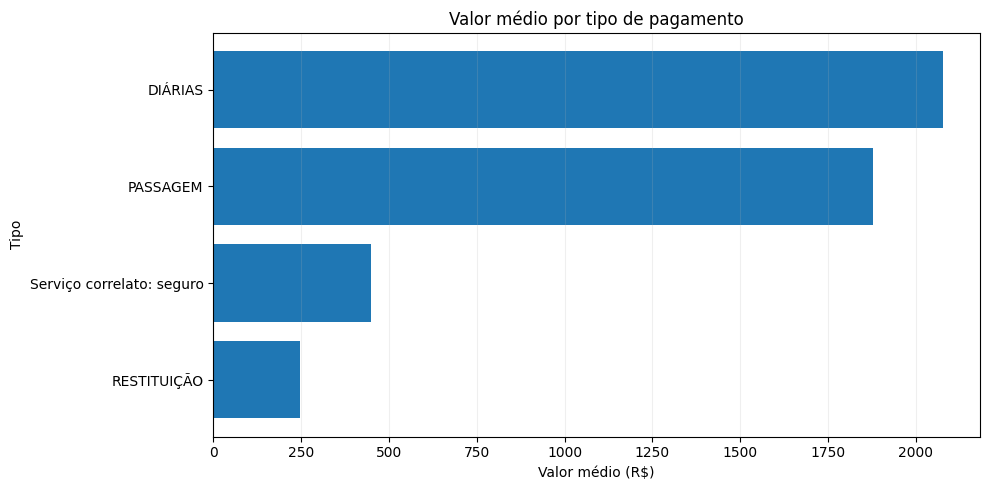

In [7]:
q4 = consultar("""
SELECT tipo_pagamento,
       ROUND(SUM(valor_pago_total)/NULLIF(SUM(qtd_pagamentos),0), 2) AS valor_medio
FROM gold_pagamentos
GROUP BY tipo_pagamento
ORDER BY valor_medio DESC NULLS LAST
""")
display(q4)
grafico(q4, 'tipo_pagamento', 'valor_medio', 'Valor médio por tipo de pagamento', 'Tipo', 'Valor médio (R$)')

## Pergunta 5 — Meio de transporte mais utilizado nos trechos

,meio_transporte,quantidade
0,Veículo Oficial,386424.0
1,Aéreo,232666.0
2,Rodoviário,64970.0
3,Veículo Próprio,42846.0
4,Inválido,26659.0
5,Fluvial,8429.0
6,Ferroviário,874.0
7,Marítimo,481.0


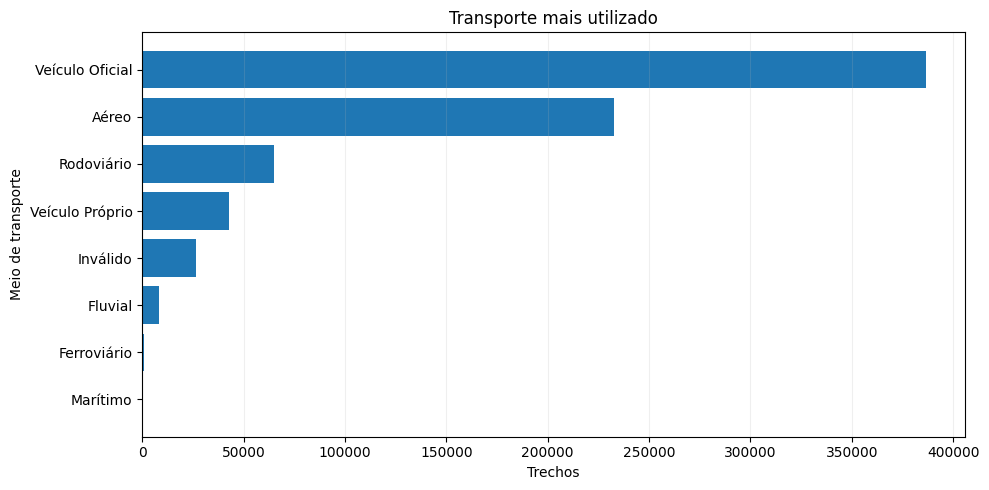

In [8]:
q5 = consultar("""
SELECT meio_transporte, SUM(qtd_trechos) AS quantidade
FROM gold_trechos
GROUP BY meio_transporte
ORDER BY quantidade DESC NULLS LAST
""")
display(q5)
grafico(q5.head(10), 'meio_transporte', 'quantidade', 'Transporte mais utilizado', 'Meio de transporte', 'Trechos')

## Pergunta 6 — UF de destino mais frequente nos trechos

,destino_uf,quantidade
0,São Paulo,82722.0
1,Distrito Federal,79962.0
2,Minas Gerais,50965.0
3,Rio de Janeiro,44197.0
4,Paraná,42603.0
5,Pará,40044.0
6,Rio Grande do Sul,38684.0
7,Mato Grosso do Sul,30516.0
8,Bahia,28375.0
9,Pernambuco,28372.0


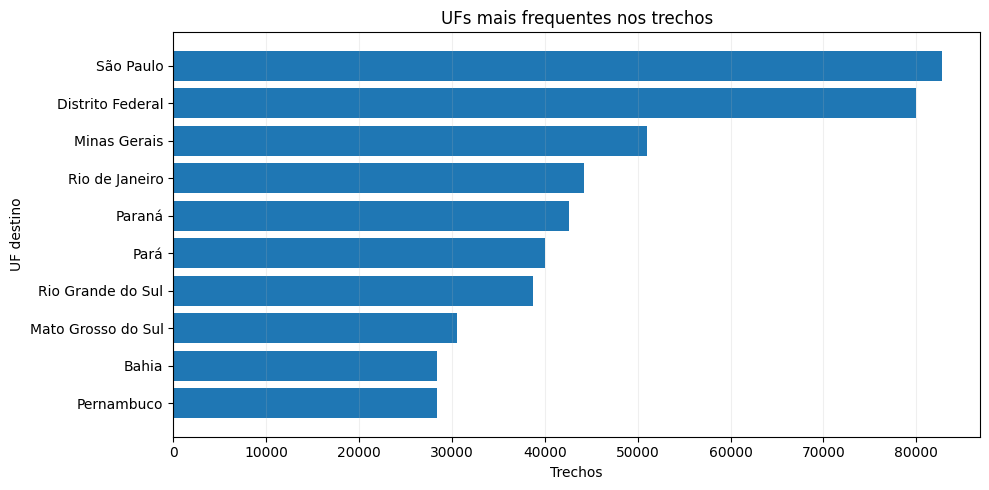

In [9]:
q6 = consultar("""
SELECT destino_uf, SUM(qtd_trechos) AS quantidade
FROM gold_trechos
WHERE destino_uf IS NOT NULL AND BTRIM(destino_uf) <> ''
GROUP BY destino_uf
ORDER BY quantidade DESC NULLS LAST
""")
display(q6)
grafico(q6.head(10), 'destino_uf', 'quantidade', 'UFs mais frequentes nos trechos', 'UF destino', 'Trechos')

## Pergunta 7 — Órgão que mais pagou no total

Aqui consideramos o **órgão pagador** da tabela de pagamentos, não o órgão superior cadastrado na viagem.

In [10]:
q7 = consultar("""
SELECT nome_orgao_pagador AS orgao_pagador,
       SUM(valor_pago_total) AS total_pago
FROM gold_pagamentos
WHERE nome_orgao_pagador IS NOT NULL
GROUP BY nome_orgao_pagador
ORDER BY total_pago DESC NULLS LAST LIMIT 10
""")
display(q7)

,orgao_pagador,total_pago
0,Fundo Nacional de Segurança Pública,2.784810e+08
1,Sigiloso,2.004848e+08
2,Comando da Aeronáutica,8.176914e+07
3,Instituto Nacional do Seguro Social,3.742760e+07
4,Comando do Exército,3.687264e+07
5,Ministério da Gestão e da Inovação em Serviços...,3.554176e+07
6,Instituto Brasileiro do Meio Ambiente e dos Re...,3.158985e+07
7,Ministério das Relações Exteriores - Unidades ...,2.560538e+07
8,Receita Federal do Brasil,2.381103e+07
9,Ministério da Agricultura e Pecuária - Unidade...,2.289988e+07


## Validação das VIEWs e tabelas físicas

In [11]:
consultar("""
SELECT 'gold_pagamentos' AS objeto, COUNT(*) AS registros FROM gold_pagamentos
UNION ALL SELECT 'vw_gold_pagamentos', COUNT(*) FROM vw_gold_pagamentos
UNION ALL SELECT 'gold_trechos', COUNT(*) FROM gold_trechos
UNION ALL SELECT 'vw_gold_trechos', COUNT(*) FROM vw_gold_trechos
""")

,objeto,registros
0,gold_trechos,201
1,gold_pagamentos,655
2,vw_gold_pagamentos,655
3,vw_gold_trechos,201


## Conclusões e limitações — preencha após executar

- **Órgãos com maior custo:** [anote o resultado da pergunta 1].
- **Destinos:** [anote os três destinos e valores].
- **Maior duração:** [anote ID, dias e custo].
- **Pagamentos:** [explique o tipo com maior média].
- **Trechos:** [explique transporte e UF].
- **Órgão pagador:** [registre nome e valor].

**Limitações:** dados restritos aos seis meses fornecidos; viagens com múltiplos destinos são associadas a mais de um destino na pergunta 2; resultados refletem registros válidos após o tratamento.